# The J++ lens, rebuilt in TorchLens

<a href="https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/wip/jfilter-lens/notebooks/jfilter_lens.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The Jacobian lens (J-lens) of [Gurnee et al. (2026)](https://transformer-circuits.pub/2026/workspace/index.html) reads an intermediate activation as the tokens the model is disposed to say: it maps the activation into the final layer with one averaged Jacobian per layer, then applies the unembedding. The **J++ lens** of Kola Ayonrinde and Jack Lindsey ([LessWrong, October 2026](https://www.lesswrong.com/posts/nc9dHfcB22JdMzGbr/j-lens-jacobian-filtering-enables-more-faithful-workspace); [code](https://github.com/safety-research/jpp_lens)) keeps that single matrix but estimates it better: it clusters the source activations, fits one "expert" Jacobian per cluster and learns weights that down-weight the experts whose readouts are poor (**Jacobian Filtering**), computes every Jacobian with Layer-wise Relevance Propagation stop-gradients (**LRP**, as in the R-lens), and ranks only tokens that contain a letter or digit (**Readout Filtering**).

This notebook rebuilds the method with [TorchLens](https://github.com/johnmarktaylor91/torchlens) on a small model and reruns the post's headline comparison (logit lens, J-lens, R-lens, J++ lens; recall@10 of intermediate variables on the post's five readout tasks). The LRP rules are three TorchLens interventions; the expert Jacobians come from the same backward passes as the plain J-lens.

In [1]:
# Colab already has torch, transformers, scikit-learn and matplotlib; this notebook was run with torchlens 3.0.3.
import subprocess
import sys

_ = subprocess.run(
    [sys.executable, "-m", "pip", "-q", "install", "torchlens>=3.0.3", "datasets"], check=True
)

## Setup

Model choice: **Qwen2.5-0.5B**. It is the smallest model in the family the post evaluates on, and it has the same block structure as the post's Qwen models (RMSNorm, a SiLU-gated MLP), so all three LRP rules apply exactly as the post specifies. It also answers more of the readout tasks' prompts correctly than GPT-2 small or SmolLM2, which matters because the post scores multihop, multilingual and poetry items only when the model gets the final answer right.

Settings follow the post (its Table 5) and the released code: WikiText-103 sequences of 128 tokens with the first 16 positions and the last dropped, routers fitted on 1,000 sequences, 8 experts per layer, and seven readout layers at block indices 3, 6, ..., 21 of 24 (the post's 64-block model reads out at block indices 8, 16, ..., 56; scaled here by 24/64). Where this notebook departs from the post:

- **16 fitting sequences for the Jacobians instead of 64**, so that a free Colab GPU finishes in about 15 minutes (the Jacobians cost one backward pass per 32 output dimensions per batch of sequences). The fit-size check near the end compares 8 with 16 sequences, and the last section reports the same code run with 64.
- **scikit-learn for the routers**: its PCA and k-means (k-means++ seeding, at most 100 Lloyd iterations) stand in for the released code's covariance-eigendecomposition PCA and torch k-means. The algorithm is the same; the random streams and stopping rules differ, so the clusters differ in detail.
- **A small model**, so fewer eval items survive the correctness filter (counts are printed in the evals section).

On CPU the notebook fits on a single sequence and 32 router sequences so that it finishes; those numbers only show that the code runs.

In [2]:
import json
import time
import urllib.request

import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import torch
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from transformers import AutoModelForCausalLM, AutoTokenizer

import torchlens as tl

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU = DEVICE == "cuda"
MODEL = "Qwen/Qwen2.5-0.5B"
N_FIT = 16 if GPU else 1  # sequences for the Jacobians (post: 64; see the setup note)
N_CLUSTER = 1000 if GPU else 32  # sequences for the k-means routers (post: 1,000)
SEQ_LEN, SKIP = 128, 16  # 128 tokens; drop the first 16 positions and the last
E = 8  # experts per layer (post: 8)
BATCH = 4 if GPU else 1  # sequences per traced forward
CHUNK = 32  # Jacobian rows per batched backward pass (a memory knob: 64 needs more than 11 GB)
SEED = 0
torch.manual_seed(SEED)
t_start = time.time()

tok = AutoTokenizer.from_pretrained(MODEL)
model = (
    AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32, attn_implementation="eager")
    .to(DEVICE)
    .eval()
)
L, D = model.config.num_hidden_layers, model.config.hidden_size
REVISION = huggingface_hub.model_info(MODEL).sha  # the model's current Hugging Face commit
BLOCKS = [f"model.layers.{i}" for i in range(L)]
LAYERS = [
    L * k // 8 for k in range(1, 8)
]  # zero-based block indices 3, 6, ..., 21, as in the released code
SOURCES = [
    BLOCKS[layer] for layer in LAYERS
]  # the residual stream at a readout layer is that block's output


def unembed(x):
    """The model's own readout: final RMSNorm, then the LM head."""
    return model.lm_head(model.model.norm(x))


print(f"{MODEL}: {L} blocks, d_model {D}, readout block indices {LAYERS}, device {DEVICE}")
print(
    f"torch {torch.__version__}, transformers {transformers.__version__}, "
    f"scikit-learn {sklearn.__version__}, torchlens {tl.__version__}, "
    f"model revision {REVISION[:12]}"
)

Qwen/Qwen2.5-0.5B: 24 blocks, d_model 896, readout block indices [3, 6, 9, 12, 15, 18, 21], device cuda
torch 2.14.1+cu126, transformers 5.22.2, scikit-learn 1.9.1, torchlens 3.0.3, model revision 060db6499f32


## The LRP rules are three TorchLens interventions

The R-lens and J++ lens compute each Jacobian through an LRP backward pass. The post's rules (its Table 5) leave every forward value unchanged and only change gradients: the **LN-rule** freezes the RMSNorm scale `rsqrt(mean(x^2) + eps)`, the **identity rule** treats `silu(z) = z * sigmoid(z)` as linear in `z` by freezing the sigmoid, and the **half rule** sends half the gradient through each side of the gated MLP's product. Attention keeps its plain gradient. In TorchLens each rule is one `tl.when(selector, edit)`: the selector picks the ops by the function they call, and the edit returns the same value with a different autograd graph. The selectors are written for Qwen2 blocks, whose only `rsqrt` calls are the RMSNorms (the cell counts the edited ops to check that); another architecture needs its own selectors and checks.

In [3]:
in_mlp = tl.in_module(f"{BLOCKS[0]}.mlp")
for block in BLOCKS[1:]:
    in_mlp = in_mlp | tl.in_module(f"{block}.mlp")


sites = {"rsqrt": 0, "silu": 0, "mul": 0}  # how many ops each rule edits in one forward pass


def ln_rule(out, *, ctx):
    """RMSNorm: hold the scale rsqrt(mean(x^2) + eps) constant."""
    sites["rsqrt"] += 1
    return out.detach()


def identity_rule(out, *, ctx):
    """SiLU: silu(z) = z * sigmoid(z), with the sigmoid held constant."""
    sites["silu"] += 1
    z = ctx.args[0]
    return z * torch.sigmoid(z).detach()


def half_rule(out, *, ctx):
    """Gated-MLP product: send half of the gradient through it."""
    sites["mul"] += 1
    return 0.5 * out + 0.5 * out.detach()


LRP = (
    tl.when(tl.func("rsqrt"), ln_rule)
    & tl.when(tl.func("silu"), identity_rule)
    & tl.when(tl.func("mul") & in_mlp, half_rule)
)


def residual_stream(ids, rules=None):
    """One traced forward. Returns the live residual stream after each readout layer and after the last block."""
    # save_mode="view" keeps the live tensors themselves, so the model's output can be differentiated with
    # respect to them; they are aliases rather than copies, so the copy-sized save budget is switched off.
    capture = tl.options.CaptureOptions(save_mode="view", save_budget=None)
    trace = tl.trace(model, ids, capture=capture, intervene=rules)
    return [trace[block].out for block in SOURCES], trace[BLOCKS[-1]].out


# The rules change gradients, never values: the LRP forward matches the plain one.
probe = tok("The rules change gradients, never values.", return_tensors="pt").input_ids.to(DEVICE)
with torch.no_grad():
    plain = residual_stream(probe)[1]
    sites.update(rsqrt=0, silu=0, mul=0)
    lrp = residual_stream(probe, LRP)[1]
print(
    f"ops edited per forward pass: {sites} (expected for Qwen2: {2 * L + 1} RMSNorms, {L} SiLUs, {L} gate products)"
)
print(
    f"largest LRP-vs-plain forward difference: {float((plain - lrp).abs().max() / plain.abs().max()):.1e} of the largest activation"
)

ops edited per forward pass: {'rsqrt': 49, 'silu': 24, 'mul': 24} (expected for Qwen2: 49 RMSNorms, 24 SiLUs, 24 gate products)
largest LRP-vs-plain forward difference: 6.9e-07 of the largest activation


## Fitting text and the k-means routers

The post clusters the residual stream at each readout layer into 8 regions: unit-normalise each activation, project onto the top 64 principal components, then k-means. `tl.extract` returns the residual stream at the seven readout layers and scikit-learn does the clustering.

In [4]:
def wikitext_sequences(n, seed):
    """n sequences of SEQ_LEN tokens, each from a different WikiText-103 paragraph with at least SEQ_LEN tokens."""
    stream = load_dataset(
        "Salesforce/wikitext", "wikitext-103-raw-v1", split="train", streaming=True
    )
    seqs = []
    for row in stream.shuffle(seed=seed, buffer_size=20_000):
        ids = tok(row["text"]).input_ids
        if len(ids) >= SEQ_LEN:
            seqs.append(ids[:SEQ_LEN])
            if len(seqs) == n:
                return torch.tensor(seqs)


fit_seqs = wikitext_sequences(N_FIT, seed=SEED)
cluster_seqs = wikitext_sequences(N_CLUSTER, seed=SEED + 1)
KEEP = slice(SKIP, SEQ_LEN - 1)

acts = [[] for _ in SOURCES]
with torch.no_grad():
    for ids in cluster_seqs.split(32):
        outs = tl.extract(model, ids.to(DEVICE), {block: block for block in SOURCES})
        for store, block in zip(acts, SOURCES):
            store.append(outs[block][:, KEEP].reshape(-1, D).float().cpu())
routers = [
    make_pipeline(
        Normalizer(),
        PCA(64, random_state=SEED),
        KMeans(E, n_init=1, max_iter=100, random_state=SEED),
    ).fit(torch.cat(a).numpy())
    for a in acts
]
del acts
print(f"routers fitted on {N_CLUSTER * (SEQ_LEN - SKIP - 1):,} positions per layer")

routers fitted on 111,000 positions per layer


## Expert Jacobians (Eq. 2a of the post)

One backward pass per chunk of output rows gives the gradient of the final residual (summed over every kept target position) with respect to the residual stream at every source position and every readout layer at once. The plain J-lens averages those per-position gradients over all positions. J++ instead sums them per k-means cluster: the same gradients, scattered into `E` accumulators. The plain average is the cluster-share-weighted sum of the raw cluster means, `J = sum_i (n_i / N) J_i`, so one fit gives both the pooled lens and its experts (the J-lens and R-lens use the raw pooled average; an expert with fewer than 50 positions is then replaced by the pooled Jacobian, as in the released code, which breaks the identity for those clusters). Like the released code, the cotangent is summed over target positions rather than averaged as the post's Eq. 1 writes, so a source position's gradient is the sum over the targets at or after it. We run it twice: once with the plain backward pass (J-lens) and once under the LRP rules (R-lens and J++).

In [5]:
def fit_experts(seqs, rules=None):
    """Per-cluster sums of d h_final / d h_layer and per-cluster position counts, for every readout layer."""
    sums = torch.zeros(len(SOURCES), E, D, D, device=DEVICE)
    counts = torch.zeros(len(SOURCES), E, device=DEVICE)
    for ids in seqs.split(BATCH):
        sources, final = residual_stream(ids.to(DEVICE), rules)
        clusters = [
            F.one_hot(
                torch.as_tensor(
                    r.predict(h[:, KEEP].reshape(-1, D).detach().cpu().numpy()), dtype=torch.long
                ),
                E,
            )
            .float()
            .to(DEVICE)
            for r, h in zip(routers, sources)
        ]
        target = final[:, KEEP].sum((0, 1))  # a cotangent at every kept target position
        for start in range(0, D, CHUNK):
            rows = torch.eye(D, device=DEVICE)[start : start + CHUNK]
            grads = torch.autograd.grad(
                target, sources, grad_outputs=rows, is_grads_batched=True, retain_graph=True
            )
            for i, (grad, onehot) in enumerate(zip(grads, clusters)):
                per_position = grad[:, :, KEEP].reshape(len(rows), -1, D)
                sums[i, :, start : start + CHUNK] += torch.einsum(
                    "rpd,pe->erd", per_position, onehot
                )
        counts += torch.stack([c.sum(0) for c in clusters])
        del sources, final, target, grads, clusters, per_position  # free this trace before the next
        if GPU:
            torch.cuda.empty_cache()
    return sums, counts


# Each half of the fitting text is fitted separately so that the fit-size check at the end costs nothing extra.
fits = {}
for name, rules in (("plain", None), ("lrp", LRP)):
    t0 = time.time()
    fits[name] = [fit_experts(part, rules) for part in fit_seqs.chunk(2)]
    print(f"{name} fit: {time.time() - t0:.0f}s")
full_fit = {
    name: (sum(s for s, _ in parts), sum(c for _, c in parts)) for name, parts in fits.items()
}


def expert_jacobians(sums, counts, min_positions=50):
    """J_i = mean over cluster i's positions; like the released code, an expert with fewer than 50 positions falls back to the pooled J."""
    pooled = sums.sum(1) / counts.sum(1)[:, None, None]
    experts = sums / counts[..., None, None].clamp(min=1)
    return torch.where((counts < min_positions)[..., None, None], pooled[:, None], experts)


shares = full_fit["lrp"][1] / full_fit["lrp"][1].sum(1, keepdim=True)
print("fit positions per expert at layer", LAYERS[0], ":", full_fit["lrp"][1][0].int().tolist())

plain fit: 184s


lrp fit: 195s
fit positions per expert at layer 3 : [192, 325, 98, 512, 181, 108, 325, 35]


## The readout evals

The post's five latent-variable tasks (data from `anthropics/jacobian-lens` via the J++ repository, Apache-2.0): multihop, multilingual, typo, association and poetry. Each item has a prompt, a readout position (the last prompt token; for poetry the end of the first line) and one or more intermediate variables. An intermediate counts as read out at a layer if any of its single-token surface forms (with or without a leading space; as written, capitalised or lowercase) is in the top 10 tokens. As in the post: multihop, multilingual and poetry items are kept only when the model answers them correctly; 20% of the items of each task form the dev set that fits the J++ weights, and every lens is scored on the other 80%.

In [6]:
EVALS = (
    "https://raw.githubusercontent.com/safety-research/jpp_lens/d7efc0de372e/data/jlens/evaluations"
)
TASKS = ["multihop", "multilingual", "typo", "association", "poetry"]


def candidates(word):
    forms = {p + w for w in {word, word.capitalize(), word.lower()} for p in ("", " ")}
    return sorted(
        {
            ids[0]
            for ids in (tok(f, add_special_tokens=False).input_ids for f in forms)
            if len(ids) == 1
        }
    )


def answers_correctly(task, item, next_token):
    """The post's correctness rule: the greedy next token is the target or a leading piece of it."""
    target = (
        item.get("target")
        if task in ("multihop", "multilingual")
        else item["intermediates"][0]
        if task == "poetry"
        else None
    )
    word = tok.decode(next_token).lstrip()
    return target is None or (bool(word) and target.strip().startswith(word))


raw = [
    (task, item)
    for task in TASKS
    for item in json.load(urllib.request.urlopen(f"{EVALS}/lens-eval-{task}.json"))["items"]
]
raw = [
    (task, item, cands)
    for task, item in raw
    if (cands := [c for c in map(candidates, item["intermediates"]) if c])
]
n_inter = sum(len(item["intermediates"]) for _, item, _ in raw)
n_kept = sum(len(cands) for _, _, cands in raw)
print(
    f"{len(raw)} items keep at least one single-token intermediate; {n_inter - n_kept} of their {n_inter} intermediates have none and are dropped"
)

484 items keep at least one single-token intermediate; 14 of their 815 intermediates have none and are dropped


In [7]:
# Right padding with causal attention: a real token never attends to the pads after it, so no mask is needed.
tok.padding_side = "right"
items = []
for start in range(0, len(raw), 32):
    group = raw[start : start + 32]
    enc = tok([item["prompt"] for _, item, _ in group], return_tensors="pt", padding=True).to(
        DEVICE
    )
    with torch.no_grad():
        outs = tl.extract(model, enc.input_ids, {block: block for block in SOURCES})
        resid = torch.stack([outs[block] for block in SOURCES], 1)  # [prompts, layers, tokens, d]
        logits = model(enc.input_ids).logits
    for b, (task, item, cands) in enumerate(group):
        n = int(enc.attention_mask[b].sum())
        pos = (
            n - 1
            if task != "poetry"
            else max(i for i in range(n) if "\n" in tok.decode(enc.input_ids[b, i]))
        )
        correct = answers_correctly(task, item, logits[b, n - 1].argmax())
        items.append(
            {
                "task": task,
                "name": item["name"],
                "cands": cands,
                "h": resid[b, :, pos],
                "correct": correct,
                "dev": False,
            }
        )

In [8]:
# The released code's split: one generator, tasks in sorted order, 20% of each task's scored items to dev.
rng = np.random.default_rng(SEED)
for task in sorted(TASKS):
    members = [it for it in items if it["task"] == task and it["correct"]]
    if not members:
        continue
    for j, k in enumerate(rng.permutation(len(members))):
        members[k]["dev"] = j < max(1, int(0.2 * len(members)))
dev = [it for it in items if it["dev"]]
test = [it for it in items if it["correct"] and not it["dev"]]
test_wrong = [it for it in items if not it["correct"]]  # secondary: prompts the model gets wrong
print(
    "scored (held-out) items:",
    {t: sum(it["task"] == t for it in test) for t in TASKS},
    "| dev items:",
    len(dev),
)
print(
    "answered correctly:",
    {
        t: f"{sum(it['correct'] for it in items if it['task'] == t)}/{sum(it['task'] == t for it in items)}"
        for t in TASKS
    },
)

# Readout Filtering: tokens with no letter or digit (the post's V_sem), sparing every scored surface form.
vocab = model.lm_head.out_features
nonsemantic = torch.tensor(
    [not any(ch.isalnum() for ch in tok.decode([i])) for i in range(vocab)], device=DEVICE
)
nonsemantic[[c for it in items for cs in it["cands"] for c in cs]] = False
print(f"Readout Filtering removes {int(nonsemantic.sum()):,} of {vocab:,} tokens")

scored (held-out) items: {'multihop': 11, 'multilingual': 10, 'typo': 77, 'association': 80, 'poetry': 0} | dev items: 42
answered correctly: {'multihop': '13/84', 'multilingual': '12/107', 'typo': '96/96', 'association': '99/99', 'poetry': '0/98'}


Readout Filtering removes 10,314 of 151,936 tokens


## Scoring

`hits` returns, for every item, layer and intermediate, whether the intermediate is in the lens's top 10 at that layer. An item's score is the fraction of its intermediates read out at any of the seven layers; the task score is the mean over its items; the headline is the macro mean over the five tasks (the post's recall@10).

In [9]:
def hits(lens, group, k=10, filtered=True, layers=None):
    """[items][layers, intermediates] booleans: is the intermediate in the lens's top k at that layer?"""
    layers = range(len(LAYERS)) if layers is None else layers
    out = []
    for it in group:
        with torch.no_grad():
            logits = torch.stack([lens(i, it["h"][i]) for i in layers])
        if filtered:
            logits = logits.masked_fill(nonsemantic, float("-inf"))
        best = torch.stack(
            [logits[:, c].max(1).values for c in it["cands"]], 1
        )  # [layers, intermediates]
        out.append(((logits[:, None, :] > best[:, :, None]).sum(-1) < k).cpu())
    return out


def recall(h, group, layer=None):
    """Macro recall@10: per item the fraction of intermediates hit (at any layer, or at one layer)."""
    per_item = np.array(
        [(x.any(0) if layer is None else x[layer]).float().mean().item() for x in h]
    )
    tasks = np.array([it["task"] for it in group])
    return float(np.mean([per_item[tasks == t].mean() for t in TASKS if (tasks == t).any()]))


def jacobian_lens(J):
    """A lens from one d_model x d_model matrix per layer: unembed(J_l h)."""
    return lambda i, h: unembed(h @ J[i].T)


def logit_lens(i, h):
    """The logit lens: the transport map is the identity."""
    return unembed(h)

## Jacobian Filtering: learning the expert weights

Per layer, the post learns one signed weight per expert on the dev items, maximising that layer's recall@10. Recall is piecewise constant in the weights, so the optimiser climbs a smooth stand-in: a sigmoid of the margin between the best candidate's logit and the 10th-largest logit, in units of the logit spread (temperature 0.1), with Adam at learning rate 0.05 for 200 steps from three starts (uniform, the best single expert, the mean of the top three), keeping the weights with the best exact dev recall (ties broken by the surrogate). The helper follows the released code (`condense_experts/`), including its weighting: the objective counts each (item, intermediate) pair once within a task, while the reported recall averages over an item's intermediates first; the two differ only for multihop and multilingual items with several intermediates. The weights are fitted per layer, while the reported recall takes the best of the seven layers. Because the final norm is an RMSNorm, the logits of `sum_i w_i J_i h` are a positive rescaling of `sum_i w_i W_U diag(g) J_i h`, so the per-expert logits are computed once per layer and the objective is linear in the weights.

In [10]:
def fit_weights(experts_l, layer, group, steps=200, lr=0.05, temperature=0.1, k=10):
    """Signed unit-norm weights over one layer's expert Jacobians, fitted on the dev items' recall@k."""
    H = torch.stack([it["h"][layer] for it in group])  # [P, d]
    with torch.no_grad():
        cache = model.lm_head(
            model.model.norm.weight * torch.einsum("edk,pk->ped", experts_l, H)
        )  # [P, E, vocab]
    pairs = [(p, c) for p, it in enumerate(group) for c in it["cands"]]
    task_of = torch.tensor([TASKS.index(group[p]["task"]) for p, _ in pairs], device=DEVICE)
    pad = max(len(c) for _, c in pairs)
    cand = torch.tensor([c + c[:1] * (pad - len(c)) for _, c in pairs], device=DEVICE)
    rows = torch.tensor([p for p, _ in pairs], device=DEVICE)

    def macro(values):
        per_task = [values[task_of == t].mean() for t in range(len(TASKS)) if (task_of == t).any()]
        return torch.stack(per_task).mean()

    def margins(w):
        logits = torch.einsum("pev,e->pv", cache, w / w.norm())[rows]
        spread = logits.std(1).detach()
        logits = logits.masked_fill(nonsemantic, float("-inf"))  # Readout Filtering
        return logits.gather(1, cand).max(1).values - logits.topk(k, 1).values[:, -1], spread

    single = torch.tensor(
        [
            macro(
                (margins(F.one_hot(torch.tensor(e), E).float().to(DEVICE))[0] >= 0).float()
            ).item()
            for e in range(E)
        ]
    )
    order = sorted(range(E), key=lambda e: (-single[e].item(), e))  # ties go to the lower index
    starts = [torch.ones(E), torch.zeros(E), torch.zeros(E)]
    starts[1][order[0]] = 1.0  # the best single expert
    starts[2][order[:3]] = 1.0  # the mean of the top three
    best = None  # (exact dev recall, surrogate, weights): ties on recall go to the higher surrogate
    for w0 in starts:
        w = (w0 / w0.norm()).to(DEVICE).requires_grad_(True)
        opt = torch.optim.Adam([w], lr=lr)
        for step in range(steps + 1):
            margin, spread = margins(w)
            surrogate = macro(torch.sigmoid(margin / (temperature * spread)))
            if step % 5 == 0 or step == steps:
                score = (macro((margin >= 0).float()).item(), surrogate.item())
                if best is None or score > best[:2]:
                    best = (*score, (w / w.norm()).detach().clone())
            if step == steps:
                break
            opt.zero_grad()
            (-surrogate).backward()
            opt.step()
    return best[2], single

In [11]:
def build_lenses(fit):
    """Every lens from one fit ({"plain" | "lrp": (per-cluster sums, counts)}): the J-, R- and J++ lenses and the no-LRP ablation."""
    experts = {name: expert_jacobians(*sc) for name, sc in fit.items()}
    pooled = {
        name: sums.sum(1) / counts.sum(1)[:, None, None] for name, (sums, counts) in fit.items()
    }
    weights = {
        name: torch.stack([fit_weights(ex[i], i, dev)[0] for i in range(len(LAYERS))])
        for name, ex in experts.items()
    }

    def mix(name):
        return jacobian_lens(torch.einsum("le,ledk->ldk", weights[name], experts[name]))

    lenses = {
        "Logit lens": logit_lens,
        "J-lens": jacobian_lens(pooled["plain"]),  # all positions averaged, plain gradient
        "R-lens": jacobian_lens(pooled["lrp"]),  # all positions averaged, LRP gradient
        "J++ lens": mix("lrp"),  # learned expert weights, LRP gradient
        "Jacobian Filtering without LRP": mix("plain"),
    }
    return lenses, experts, weights


t0 = time.time()
all_lenses, experts, weights = build_lenses(full_fit)
print(f"weights fitted in {time.time() - t0:.0f}s")
print("J++ weights at the first readout layer:", [round(x, 2) for x in weights["lrp"][0].tolist()])

weights fitted in 45s
J++ weights at the first readout layer: [-0.19, -0.17, -0.36, 0.75, 0.46, 0.16, -0.01, 0.13]


## The comparison

In [12]:
lenses = {name: all_lenses[name] for name in ("Logit lens", "J-lens", "R-lens", "J++ lens")}
H = {name: hits(lens, test) for name, lens in lenses.items()}
H["J++ without Readout Filtering"] = hits(lenses["J++ lens"], test, filtered=False)
H["Jacobian Filtering without LRP"] = hits(all_lenses["Jacobian Filtering without LRP"], test)
H["J-lens, unfiltered readout"] = hits(lenses["J-lens"], test, filtered=False)


def bootstrap(h, group, n=1000):
    """95% interval of the macro recall, resampling items within each task."""
    tasks = np.array([it["task"] for it in group])
    per_item = np.array([x.any(0).float().mean().item() for x in h])
    draws = np.random.default_rng(SEED)
    present = [t for t in TASKS if (tasks == t).any()]
    stats = [
        np.mean([draws.choice(per_item[tasks == t], (tasks == t).sum()).mean() for t in present])
        for _ in range(n)
    ]
    return np.percentile(stats, [2.5, 97.5])


def per_task(h, group):
    per_item = np.array([x.any(0).float().mean().item() for x in h])
    tasks = np.array([it["task"] for it in group])
    return [per_item[tasks == t].mean() if (tasks == t).any() else float("nan") for t in TASKS]


def table(H, group):
    print(f"{'lens':34s} {'macro':>6s}   95% CI         " + " ".join(f"{t[:8]:>8s}" for t in TASKS))
    for name, h in H.items():
        lo, hi = bootstrap(h, group)
        print(
            f"{name:34s} {100 * recall(h, group):6.1f}   [{100 * lo:4.1f}, {100 * hi:4.1f}]   "
            + " ".join(f"{100 * v:8.1f}" for v in per_task(h, group))
        )


print(
    "Recall@10 (%) on held-out items the model answers correctly (the post's protocol); nan = no such items"
)
table(H, test)
print(
    "\nSecondary check, the prompts the model answers wrongly (multihop, multilingual, poetry only):"
)
table({name: hits(lens, test_wrong) for name, lens in lenses.items()}, test_wrong)


def paired_difference(h_a, h_b, group, n=1000):
    """Macro recall of lens a minus lens b, with a 95% interval from resampling the same items for both."""
    tasks = np.array([it["task"] for it in group])
    diff = np.array(
        [a.any(0).float().mean().item() - b.any(0).float().mean().item() for a, b in zip(h_a, h_b)]
    )
    draws = np.random.default_rng(SEED)
    present = [t for t in TASKS if (tasks == t).any()]
    stats = [
        np.mean([draws.choice(diff[tasks == t], (tasks == t).sum()).mean() for t in present])
        for _ in range(n)
    ]
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return np.mean([diff[tasks == t].mean() for t in present]), lo, hi


print(
    "\nPaired differences in macro recall@10 (points; 95% interval from resampling the same eval items for both lenses,"
    " so it covers eval-item noise only, not the fitting text, routers or dev split):"
)
for a, b in [
    ("J++ lens", "R-lens"),
    ("J++ lens", "J-lens"),
    ("J++ lens", "Jacobian Filtering without LRP"),
]:
    d, lo, hi = paired_difference(H[a], H[b], test)
    print(f"  {a} minus {b}: {100 * d:+.1f}  [{100 * lo:+.1f}, {100 * hi:+.1f}]")
print(f"\ntotal wall time so far: {(time.time() - t_start) / 60:.1f} min")

Recall@10 (%) on held-out items the model answers correctly (the post's protocol); nan = no such items
lens                                macro   95% CI         multihop multilin     typo associat   poetry
Logit lens                           12.6   [ 5.2, 20.0]       36.4     10.0      3.9      0.0      nan
J-lens                               38.2   [30.6, 46.2]       54.5     33.3     63.6      1.2      nan


R-lens                               37.9   [30.2, 45.4]       54.5     28.3     67.5      1.2      nan
J++ lens                             39.5   [32.0, 46.9]       54.5     30.8     72.7      0.0      nan


J++ without Readout Filtering        38.9   [31.4, 46.1]       54.5     30.8     70.1      0.0      nan
Jacobian Filtering without LRP       43.4   [35.9, 51.2]       54.5     35.8     81.8      1.2      nan
J-lens, unfiltered readout           33.3   [25.9, 41.5]       54.5     33.3     45.5      0.0      nan

Secondary check, the prompts the model answers wrongly (multihop, multilingual, poetry only):


lens                                macro   95% CI         multihop multilin     typo associat   poetry
Logit lens                            8.8   [ 5.9, 12.0]       19.7      6.7      nan      nan      0.0
J-lens                               18.8   [15.3, 22.8]       26.1     30.3      nan      nan      0.0


R-lens                               20.5   [16.6, 24.6]       38.7     22.9      nan      nan      0.0
J++ lens                             16.3   [12.8, 20.3]       26.8     21.2      nan      nan      1.0

Paired differences in macro recall@10 (points; 95% interval from resampling the same eval items for both lenses, so it covers eval-item noise only, not the fitting text, routers or dev split):
  J++ lens minus R-lens: +1.6  [-0.9, +4.2]


  J++ lens minus J-lens: +1.3  [-1.6, +4.2]
  J++ lens minus Jacobian Filtering without LRP: -3.8  [-6.7, -1.2]

total wall time so far: 8.4 min


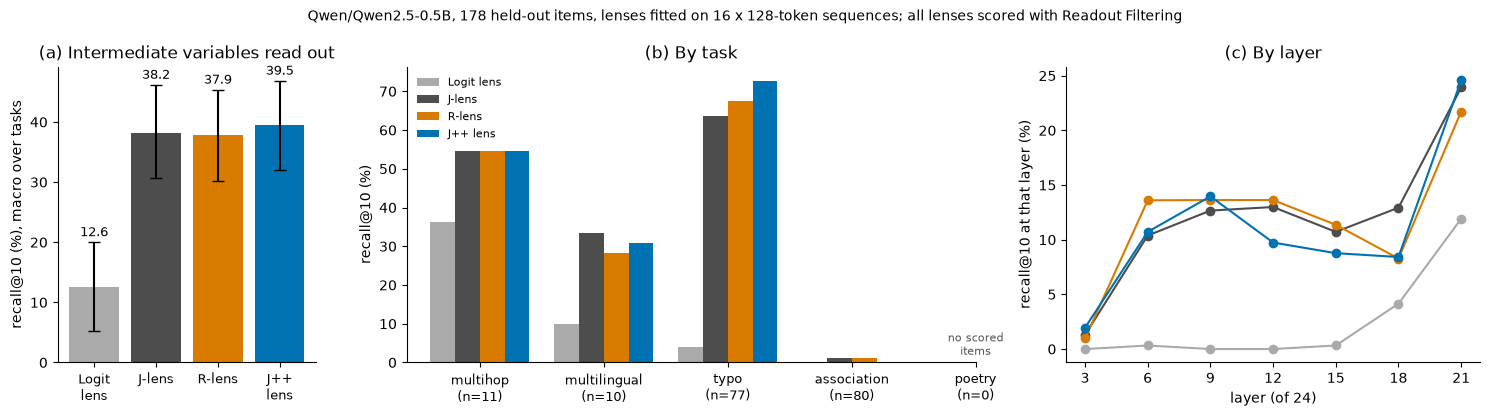

In [13]:
colors = {"Logit lens": "#AAAAAA", "J-lens": "#4D4D4D", "R-lens": "#D97B00", "J++ lens": "#0072B2"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2.2, 1.6]})
ax = axes[0]
for x, name in enumerate(lenses):
    lo, hi = bootstrap(H[name], test)
    r = recall(H[name], test)
    ax.bar(x, 100 * r, color=colors[name], yerr=[[100 * (r - lo)], [100 * (hi - r)]], capsize=4)
    ax.text(x, 100 * hi + 1, f"{100 * r:.1f}", ha="center", fontsize=9)
ax.set_xticks(range(len(lenses)), [n.replace(" lens", "\nlens") for n in lenses], fontsize=9)
ax.set_ylabel("recall@10 (%), macro over tasks")
ax.set_title("(a) Intermediate variables read out")
ax = axes[1]
width = 0.2
for j, name in enumerate(lenses):
    ax.bar(
        np.arange(len(TASKS)) + (j - 1.5) * width,
        100 * np.array(per_task(H[name], test)),
        width,
        color=colors[name],
        label=name,
    )
counts = [sum(it["task"] == t for it in test) for t in TASKS]
ax.set_xticks(range(len(TASKS)), [f"{t}\n(n={c})" for t, c in zip(TASKS, counts)], fontsize=9)
ax.set_title("(b) By task")
ax.set_ylabel("recall@10 (%)")
for x, (t, c) in enumerate(zip(TASKS, counts)):
    scores = [per_task(H[name], test)[x] for name in lenses]
    if c == 0:
        ax.text(x, 2, "no scored\nitems", ha="center", fontsize=8, color="#555555")
    elif max(scores) == 0:
        ax.text(x, 2, "0 for\nevery lens", ha="center", fontsize=8, color="#555555")
ax.legend(fontsize=8, frameon=False)
ax = axes[2]
for name in lenses:
    ax.plot(
        LAYERS,
        [100 * recall(H[name], test, layer=i) for i in range(len(LAYERS))],
        "o-",
        color=colors[name],
        label=name,
    )
ax.set_xlabel(f"layer (of {L})")
ax.set_ylabel("recall@10 at that layer (%)")
ax.set_title("(c) By layer")
ax.set_xticks(LAYERS)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle(
    f"{MODEL}, {len(test)} held-out items, lenses fitted on {N_FIT} x {SEQ_LEN}-token sequences; all lenses scored with Readout Filtering",
    fontsize=10,
)
plt.tight_layout()
plt.show()

## Why filtering helps: the experts are uneven

The post's Figure 3 applies each expert Jacobian alone, at its own layer, to every eval item. Some experts read out intermediates well even outside their own cluster; others are close to useless, and the pooled Jacobian (the cluster-share-weighted average) mixes them all in. The learned weights mostly decide which experts to drop.

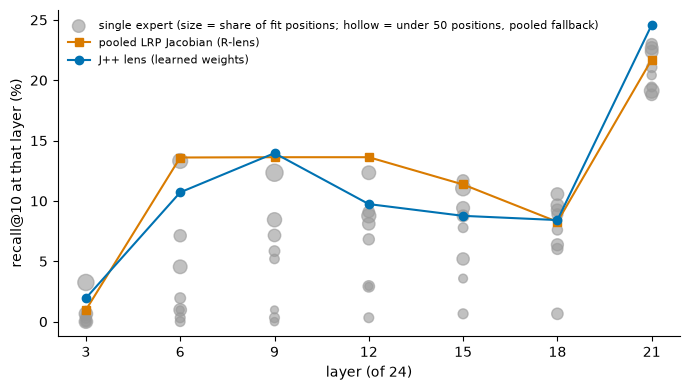

learned weights (rows: layers, columns: experts):
[[-0.19 -0.17 -0.36  0.75  0.46  0.16 -0.01  0.13]
 [ 0.04  0.62  0.02  0.59 -0.35 -0.08 -0.28 -0.24]
 [-0.03  0.08  0.78  0.09  0.46 -0.03 -0.39 -0.11]
 [-0.19 -0.37  0.68  0.14  0.21  0.06 -0.38  0.38]
 [-0.06 -0.23 -0.09 -0.   -0.32  0.21  0.86  0.21]
 [ 0.63 -0.08  0.1   0.14 -0.4   0.57 -0.21 -0.2 ]
 [ 0.39  0.6   0.02  0.23  0.24  0.35 -0.5  -0.02]]


In [14]:
expert_recall = np.zeros((len(LAYERS), E))
for i in range(len(LAYERS)):
    for e in range(E):
        one_expert = jacobian_lens({i: experts["lrp"][i, e]})
        expert_recall[i, e] = recall(hits(one_expert, test, layers=[i]), test, layer=0)
fig, ax = plt.subplots(figsize=(7, 4))
fallback = (full_fit["lrp"][1] < 50).cpu().numpy()  # experts replaced by the pooled Jacobian
for i, layer in enumerate(LAYERS):
    ax.scatter(
        [layer] * E,
        100 * expert_recall[i],
        s=20 + 400 * shares[i].cpu().numpy(),
        facecolors=np.where(fallback[i], "none", "#999999"),
        edgecolors="#999999",
        alpha=0.6,
        label="single expert (size = share of fit positions; hollow = under 50 positions, pooled fallback)"
        if i == 0
        else None,
    )
ax.plot(
    LAYERS,
    [100 * recall(H["R-lens"], test, layer=i) for i in range(len(LAYERS))],
    "s-",
    color=colors["R-lens"],
    label="pooled LRP Jacobian (R-lens)",
)
ax.plot(
    LAYERS,
    [100 * recall(H["J++ lens"], test, layer=i) for i in range(len(LAYERS))],
    "o-",
    color=colors["J++ lens"],
    label="J++ lens (learned weights)",
)
ax.set_xlabel(f"layer (of {L})")
ax.set_xticks(LAYERS)
ax.set_ylabel("recall@10 at that layer (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()
print("learned weights (rows: layers, columns: experts):")
print(np.round(weights["lrp"].cpu().numpy(), 2))

## Fit size: is 16 sequences enough?

The two halves of the fitting text were fitted separately, so the lenses can be rebuilt from the first half alone (8 sequences on the default GPU setting) at no extra cost. Rebuilding refits the J++ weights too, so the last row also scores the half-fit experts with the full fit's weights held fixed, which changes only the Jacobians. One run per setting cannot separate fitting noise from a real trend; the numbers say how much the aggregate recall moved in this run.

In [15]:
if len(fits["lrp"]) == 2:
    half_lenses, _, _ = build_lenses({name: parts[0] for name, parts in fits.items()})
    print(f"{'lens':12s} {'half fit':>9s} {'full fit':>9s}   (macro recall@10 %, held-out items)")
    for name in lenses:
        print(
            f"{name:12s} {100 * recall(hits(half_lenses[name], test), test):9.1f} {100 * recall(H[name], test):9.1f}"
        )
    half_experts = expert_jacobians(*fits["lrp"][0])
    fixed = jacobian_lens(torch.einsum("le,ledk->ldk", weights["lrp"], half_experts))
    print(
        f"{'J++ lens, half-fit experts with the full fit weights':52s} {100 * recall(hits(fixed, test), test):5.1f}"
    )
print(f"total wall time: {(time.time() - t_start) / 60:.1f} min")

lens          half fit  full fit   (macro recall@10 %, held-out items)


Logit lens        12.6      12.6


J-lens            38.2      38.2


R-lens            38.6      37.9


J++ lens          40.8      39.5


J++ lens, half-fit experts with the full fit weights  40.8
total wall time: 9.6 min


## What this shows

On Qwen2.5-0.5B the J++ lens scores highest of the post's four headline lenses, but only by 1 to 3 points, and the paired intervals include zero; the post's large gain does not reproduce at this scale.

Macro recall@10 (%) on held-out items the model answers correctly, averaged over the **four** tasks that have such items (poetry has none here); the post averages over five, so its column is context, not a like-for-like target. The first column is the run above (16 fitting sequences); the second is the same code with `N_FIT = 64`, the post's Jacobian fitting count (about 27 minutes of fitting on an RTX 2080 Ti; torch 2.14.1, transformers 5.22.2, scikit-learn 1.9.1, torchlens 3.0.3); the third is the post's Qwen3.6-27B (its Figure 1 and Tables 2 and 3b).

| Lens | 16 sequences | 64 sequences | Post, Qwen3.6-27B (5 tasks) |
|---|---:|---:|---:|
| Logit lens | 12.6 | 12.6 | 31.1 |
| J-lens | 38.2 | 36.6 | 35.7 |
| R-lens | 37.9 | 36.9 | 37.7 |
| **J++ lens** | **39.5** | **39.2** | **55.2** |
| J++ without Readout Filtering | 38.9 | 38.6 | 52.3 |
| Jacobian Filtering without LRP | 43.4 | 39.3 | 48.6 |

Paired differences (points, 95% interval over eval items only): J++ minus R-lens +1.6 [-0.9, +4.2] at 16 sequences and +2.3 [-0.3, +5.4] at 64; J++ minus J-lens +1.3 [-1.6, +4.2] and +2.7 [-0.2, +5.6]. These intervals hold the fitted lenses fixed; a different fitting text, router seed or dev split would add variance on top.

What matches the post:

- The Jacobian lenses read out about three times as many intermediates as the logit lens (the 27B model's logit lens is much stronger, so the post's gap is smaller).
- J++ is the best of the four headline lenses in both runs, and its gain is clearest on typo, the task with the most items (64 sequences: J-lens 57.1, R-lens 63.6, J++ 74.0; the post: 60.4, 66.7, 91.7).
- Readout Filtering helps J++ slightly (38.6 without it, 39.2 with it at 64 sequences; the post: 52.3 and 55.2), and helps the J-lens more (32.4 without it, 36.6 with it).
- The experts are uneven (the scatter above): at each layer single experts range from near zero to around the pooled Jacobian, and the learned weights are signed and far from the cluster shares.

What does not match, and why these numbers are weak evidence either way:

- The margin is small: about 2 points over the R-lens against 17.5 in the post. Only 178 held-out items are scored (11 multihop, 10 multilingual, 77 typo, 80 association), because this model answers few multihop and multilingual prompts and no poetry prompt correctly; the weights are fitted on 42 dev items.
- Association is close to 0 for every lens (at most 1.2%; the post's 27B model: 9 to 37%), so a quarter of the four-task average carries almost no signal.
- The LRP rules do not help here. At 16 sequences, Jacobian Filtering without LRP beats J++ by 3.8 points [1.2, 6.7]; at 64 sequences the two are level (-0.0 [-3.5, +4.4]). The post finds J++ 6.6 points above its no-LRP ablation.
- On the prompts the model answers wrongly (the secondary table; multihop and multilingual), J++ is slightly below the J-lens and R-lens (64 sequences: 16.4 against 18.3 and 17.6). The weights were fitted on correctly answered items.
- Fit size: in these runs aggregate recall changed little between 8, 16 and 64 sequences (J-lens 38.2, 38.2, 36.6; J++ 40.8, 39.5, 39.2), and scoring the 8-sequence experts with the 16-sequence weights gave the same J++ score as refitting them. One run per setting does not show that the Jacobians have converged; it shows that more fitting text did not change the conclusion here.

A fair test of the post's claim needs a model that answers more of the readout prompts correctly (the post's smallest model has 9B parameters) or a larger evaluation set. The code is written for Qwen2-style blocks (RMSNorm, SiLU-gated MLP, bias-free LM head); another architecture needs its own LRP selectors, a check of which ops they edit, and a check of the cached-logit shortcut in the weight fit.